In [1]:
import pandas as pd

df = pd.read_csv("../Data/Mall_Customers.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:
# Step 2: Understand the Dataset

print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows:
0

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [3]:
# Step 3: Check Columns and Data Types

print("Column Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nUnique Values:")
for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

Column Names:
Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

Data Types:
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

Unique Values:
CustomerID: 200 unique values
Gender: 2 unique values
Age: 51 unique values
Annual Income (k$): 64 unique values
Spending Score (1-100): 84 unique values


In [4]:
# Step 4: Create Classification Target

df["Spending_Category"] = df["Spending Score (1-100)"].apply(
    lambda x: "High Spender" if x >= 60 else "Low Spender"
)

print(df["Spending_Category"].value_counts())

print("\nTarget Distribution:")
print(df["Spending_Category"].value_counts(normalize=True) * 100)

Spending_Category
Low Spender     135
High Spender     65
Name: count, dtype: int64

Target Distribution:
Spending_Category
Low Spender     67.5
High Spender    32.5
Name: proportion, dtype: float64


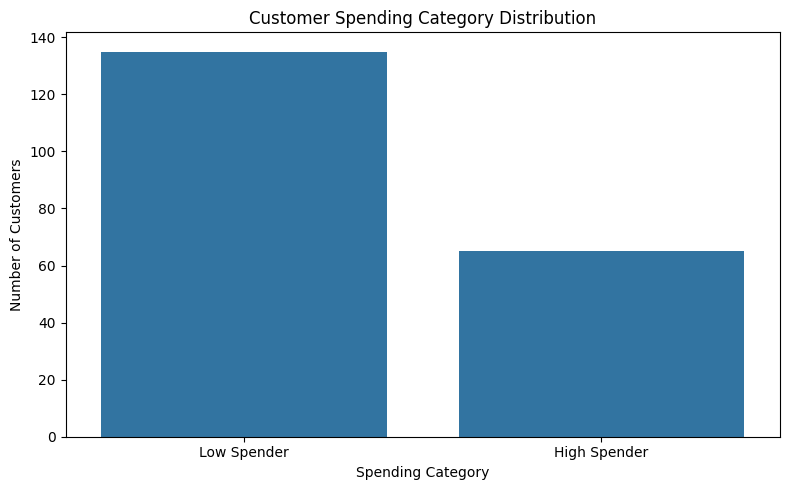

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Spending_Category")

plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

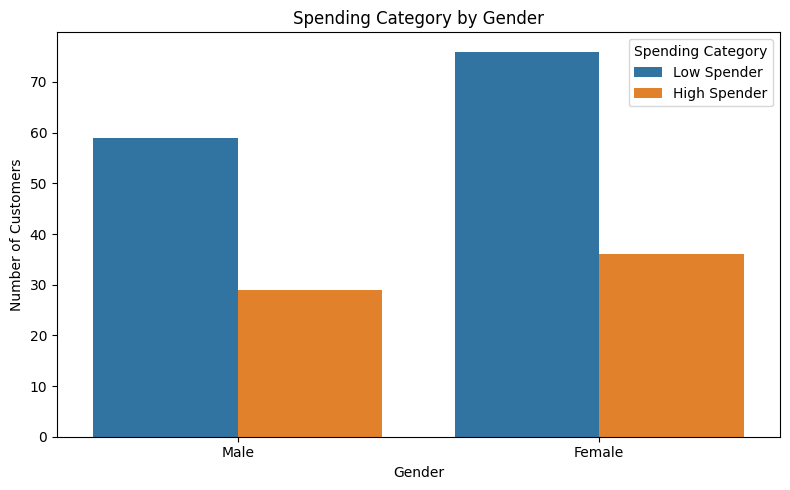

In [8]:
# Step 6: Gender vs Spending Category

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="Spending_Category"
)

plt.title("Spending Category by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.legend(title="Spending Category")

plt.tight_layout()
plt.show()

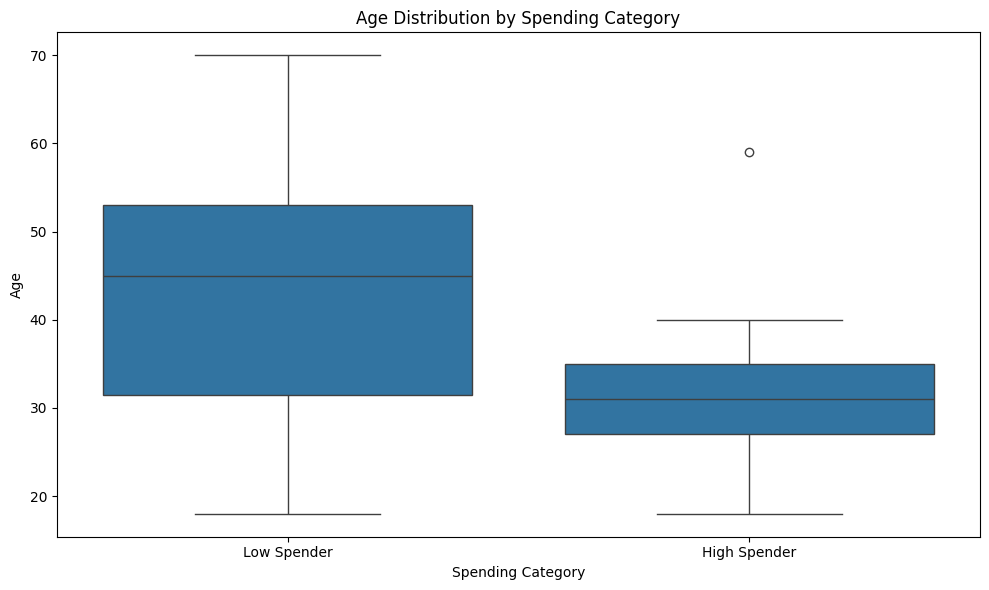

In [9]:
# Step 7: Age vs Spending Category

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Spending_Category",
    y="Age"
)

plt.title("Age Distribution by Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Age")

plt.tight_layout()
plt.show()

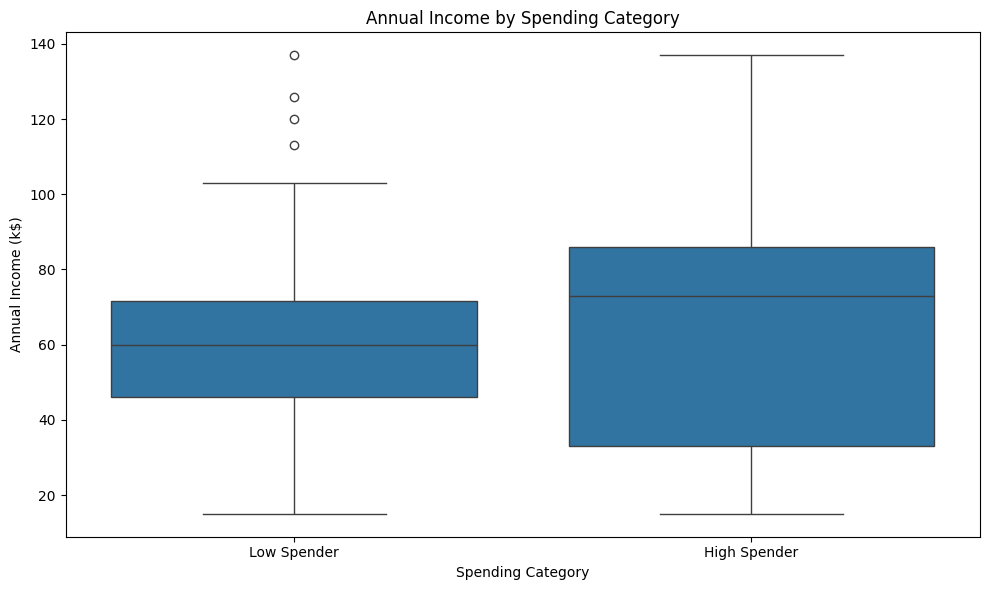

In [10]:
# Step 8: Annual Income vs Spending Category

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Spending_Category",
    y="Annual Income (k$)"
)

plt.title("Annual Income by Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Annual Income (k$)")

plt.tight_layout()
plt.show()

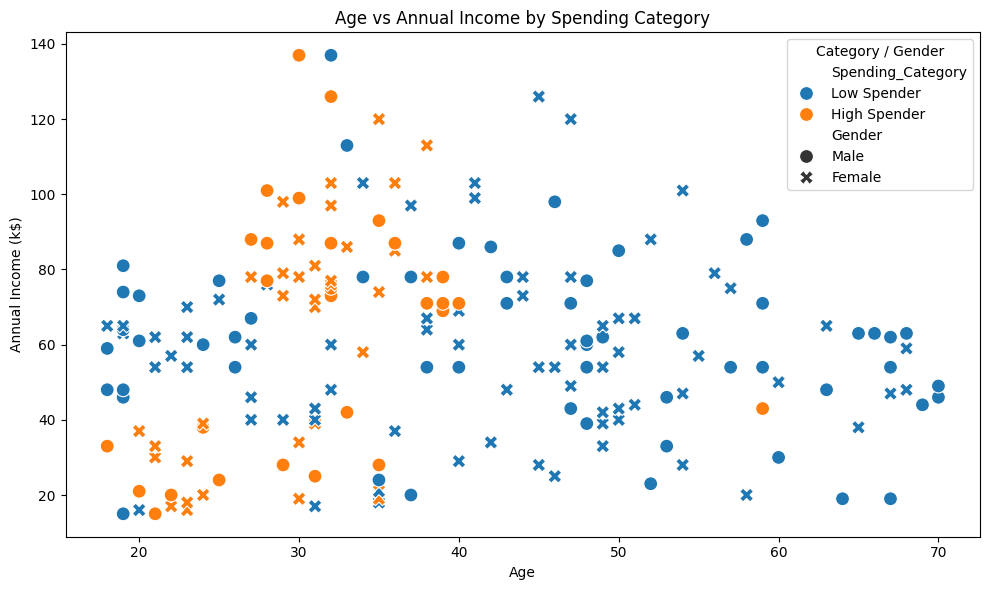

In [11]:
# Step 9: Age vs Annual Income

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Annual Income (k$)",
    hue="Spending_Category",
    style="Gender",
    s=100
)

plt.title("Age vs Annual Income by Spending Category")
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")
plt.legend(title="Category / Gender")

plt.tight_layout()
plt.show()

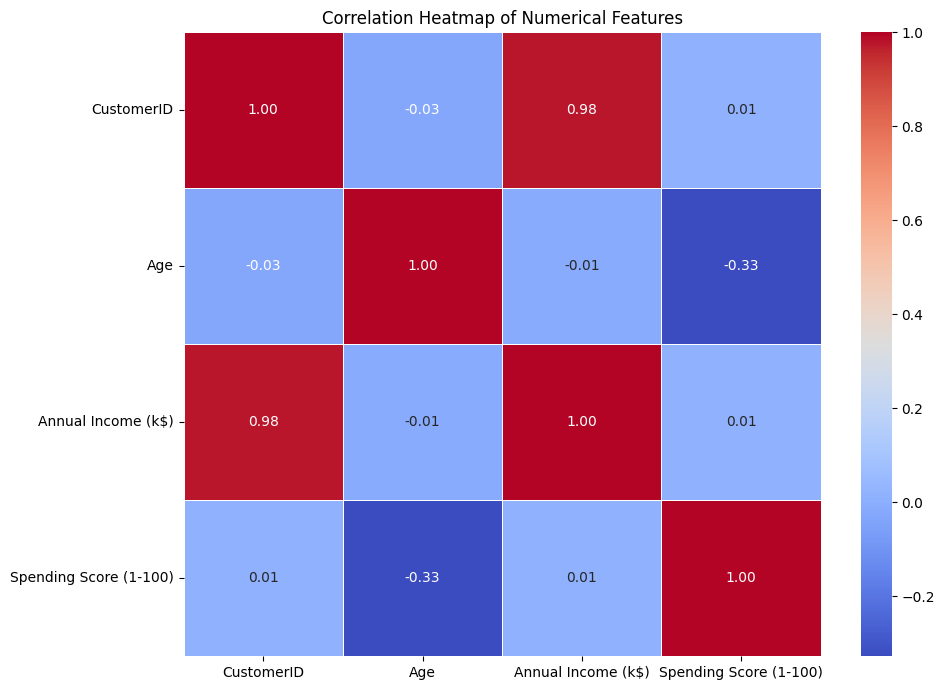

In [12]:
# Step 10: Correlation Heatmap

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

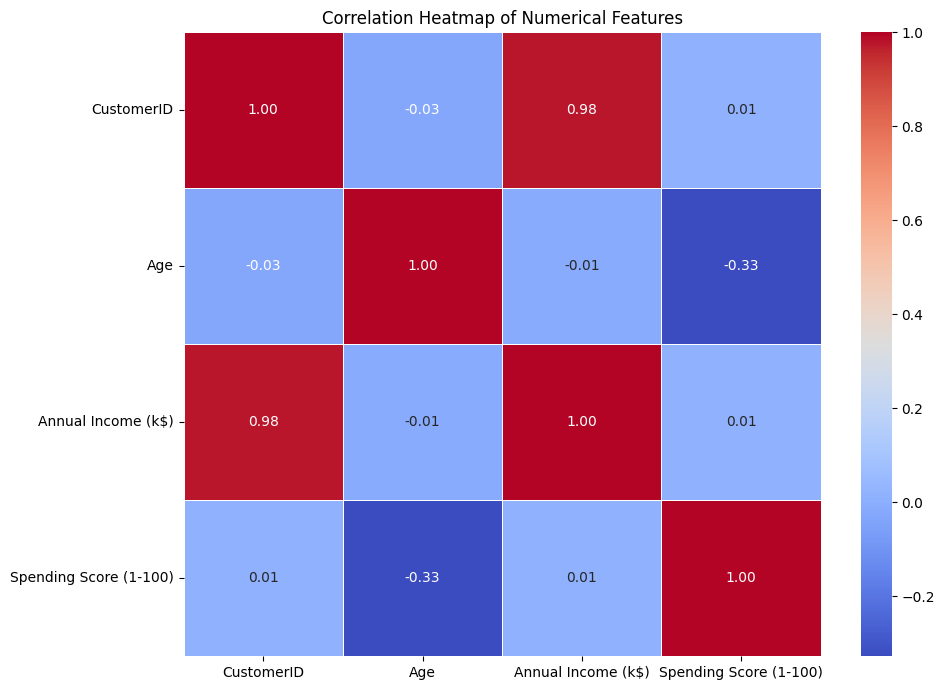

In [13]:
# Step 11: Save Correlation Heatmap

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()

plt.savefig("../Images/correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

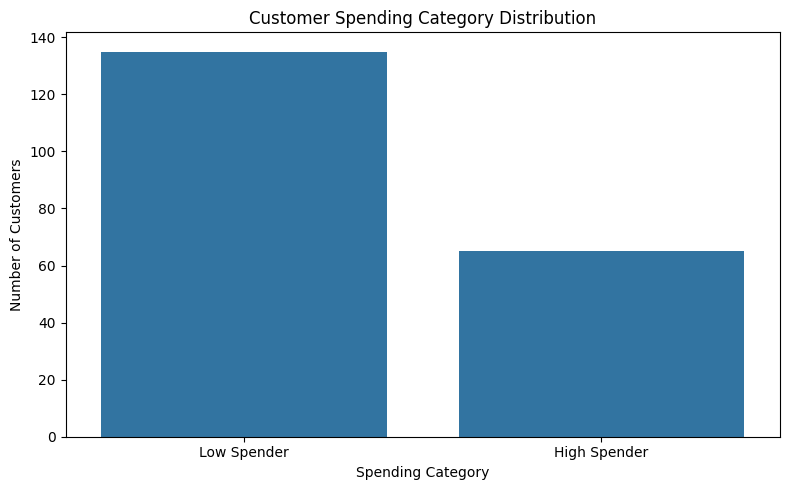

In [14]:
# Step 12: Save Spending Category Distribution

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Spending_Category")

plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../Images/spending_category_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

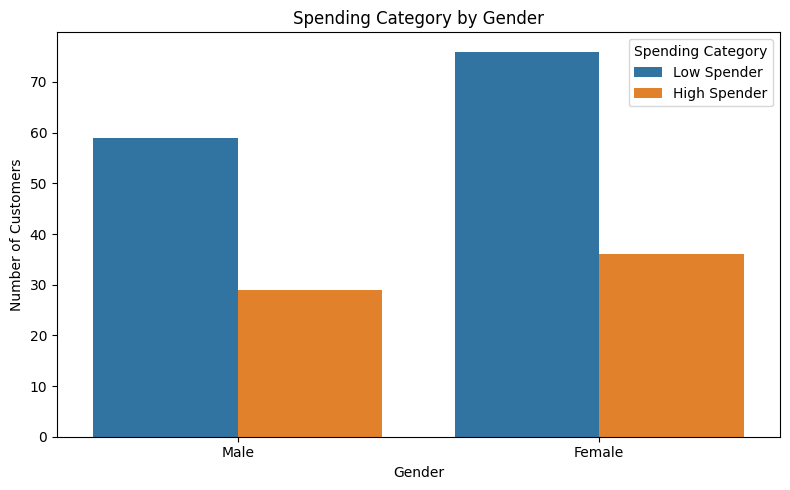

In [15]:
# Step 13: Save Gender vs Spending Category Chart

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="Spending_Category"
)

plt.title("Spending Category by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.legend(title="Spending Category")

plt.tight_layout()

plt.savefig(
    "../Images/gender_vs_spending_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

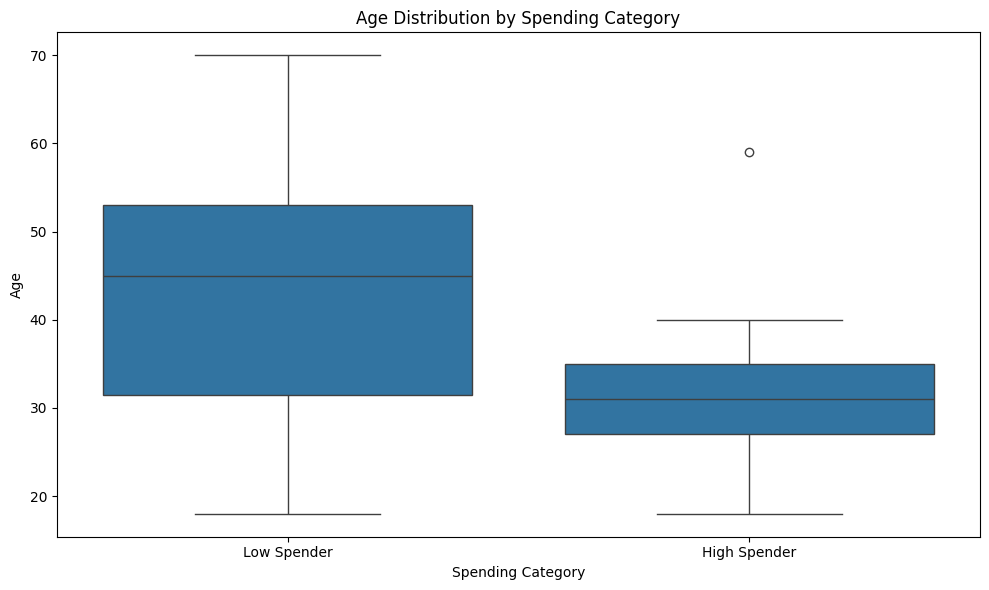

In [16]:
# Step 14: Save Age vs Spending Category

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Spending_Category",
    y="Age"
)

plt.title("Age Distribution by Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Age")

plt.tight_layout()

plt.savefig(
    "../Images/age_vs_spending_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

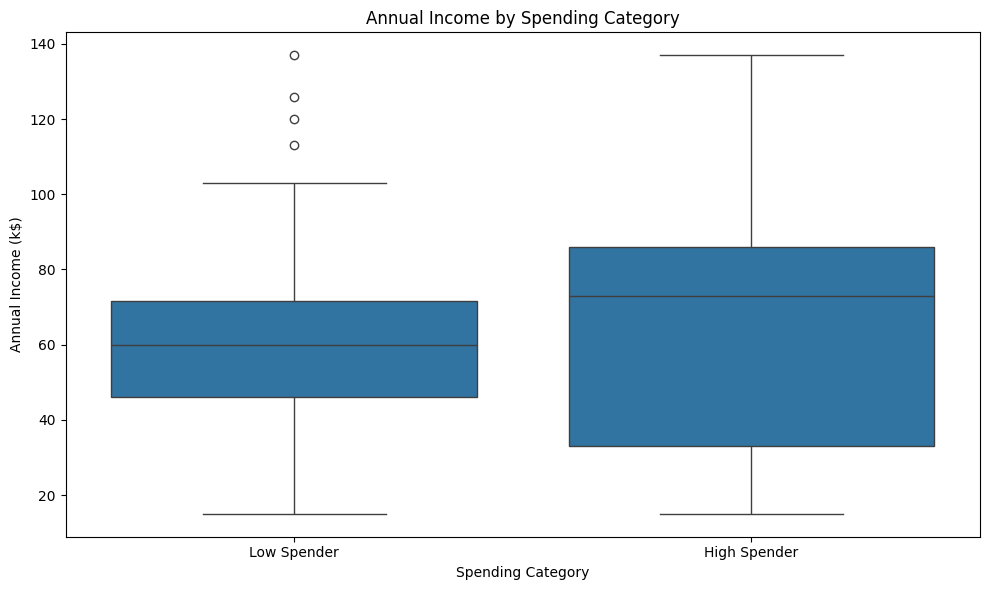

In [17]:
# Step 15: Save Annual Income vs Spending Category

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Spending_Category",
    y="Annual Income (k$)"
)

plt.title("Annual Income by Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Annual Income (k$)")

plt.tight_layout()

plt.savefig(
    "../Images/income_vs_spending_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

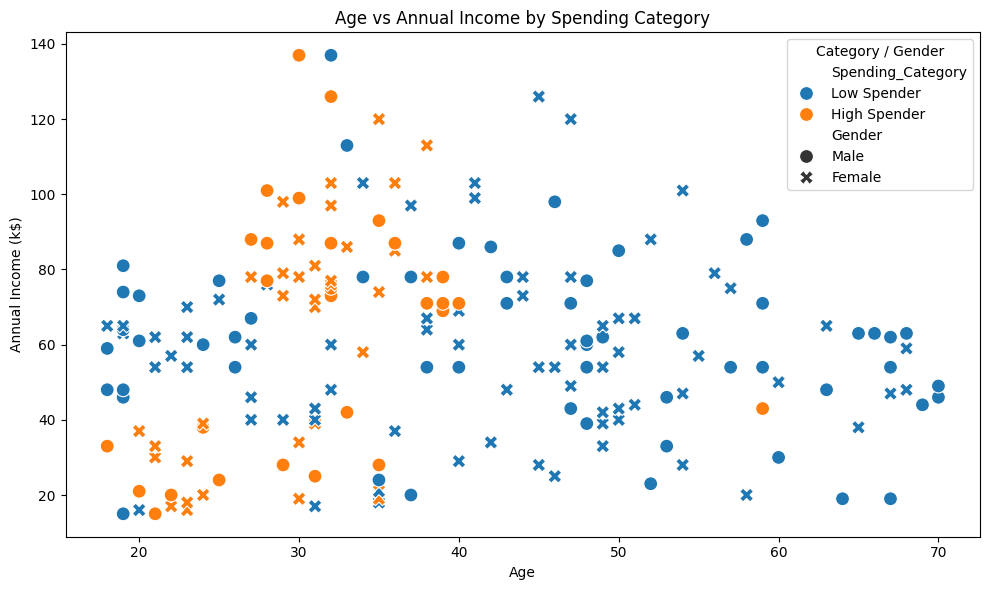

In [18]:
# Step 16: Save Age vs Annual Income

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Annual Income (k$)",
    hue="Spending_Category",
    style="Gender",
    s=100
)

plt.title("Age vs Annual Income by Spending Category")
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")
plt.legend(title="Category / Gender")

plt.tight_layout()

plt.savefig(
    "../Images/age_vs_income_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
# Step 17: Prepare Features and Target

# Features
X = df[[
    "Gender",
    "Age",
    "Annual Income (k$)"
]]

# Target
y = df["Spending_Category"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Features (X):
   Gender  Age  Annual Income (k$)
0    Male   19                  15
1    Male   21                  15
2  Female   20                  16
3  Female   23                  16
4  Female   31                  17

Target (y):
0     Low Spender
1    High Spender
2     Low Spender
3    High Spender
4     Low Spender
Name: Spending_Category, dtype: object

X Shape: (200, 3)
y Shape: (200,)


In [20]:
# Step 18: Encode Categorical Feature

X_encoded = pd.get_dummies(
    X,
    columns=["Gender"],
    drop_first=True,
    dtype=int
)

print("Encoded Features:")
print(X_encoded.head())

print("\nNew Columns:")
print(X_encoded.columns.tolist())

print("\nShape:", X_encoded.shape)

Encoded Features:
   Age  Annual Income (k$)  Gender_Male
0   19                  15            1
1   21                  15            1
2   20                  16            0
3   23                  16            0
4   31                  17            0

New Columns:
['Age', 'Annual Income (k$)', 'Gender_Male']

Shape: (200, 3)


In [21]:
# Step 19: Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:")
print(y_train.value_counts())

print("\nTesting Target:")
print(y_test.value_counts())

Training Features: (160, 3)
Testing Features: (40, 3)

Training Target:
Spending_Category
Low Spender     108
High Spender     52
Name: count, dtype: int64

Testing Target:
Spending_Category
Low Spender     27
High Spender    13
Name: count, dtype: int64


In [22]:
# Step 20: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Testing Data:")
print(X_test_scaled[:5])

Scaled Training Data:
[[ 0.69194558 -0.28718727 -0.89317009]
 [ 2.13162429 -0.65775149  1.11960758]
 [-0.60376526 -0.80597717 -0.89317009]
 [ 0.40400984 -0.28718727 -0.89317009]
 [-0.60376526 -0.69480791 -0.89317009]]

Scaled Testing Data:
[[-1.25162068 -1.54710561  1.11960758]
 [ 0.40400984 -1.25065423 -0.89317009]
 [-1.03566887 -1.39887992  1.11960758]
 [-0.891701   -0.06484874 -0.89317009]
 [ 0.3320259   0.41688474 -0.89317009]]


In [23]:
# Step 21: Logistic Regression

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(random_state=42)

logistic_model.fit(X_train_scaled, y_train)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Predictions:")
print(y_pred_logistic[:10])

Predictions:
['High Spender' 'Low Spender' 'Low Spender' 'High Spender' 'Low Spender'
 'Low Spender' 'Low Spender' 'High Spender' 'High Spender' 'High Spender']


In [24]:
# Step 22: Evaluate Logistic Regression

from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Accuracy: 0.55

Classification Report:
              precision    recall  f1-score   support

High Spender       0.31      0.31      0.31        13
 Low Spender       0.67      0.67      0.67        27

    accuracy                           0.55        40
   macro avg       0.49      0.49      0.49        40
weighted avg       0.55      0.55      0.55        40



In [25]:
# Step 23: Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=4
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("Decision Tree Predictions:")
print(y_pred_tree[:10])

Decision Tree Predictions:
['High Spender' 'Low Spender' 'High Spender' 'Low Spender' 'Low Spender'
 'High Spender' 'Low Spender' 'Low Spender' 'Low Spender' 'Low Spender']


In [26]:
# Step 24: Evaluate Decision Tree

from sklearn.metrics import accuracy_score, classification_report

accuracy_tree = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", accuracy_tree)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

High Spender       0.85      0.85      0.85        13
 Low Spender       0.93      0.93      0.93        27

    accuracy                           0.90        40
   macro avg       0.89      0.89      0.89        40
weighted avg       0.90      0.90      0.90        40



In [27]:
# Step 25: Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=5
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(y_pred_rf[:10])

Random Forest Predictions:
['High Spender' 'Low Spender' 'High Spender' 'Low Spender' 'Low Spender'
 'High Spender' 'Low Spender' 'Low Spender' 'Low Spender' 'Low Spender']


In [28]:
# Step 26: Evaluate Random Forest

from sklearn.metrics import accuracy_score, classification_report

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.875

Classification Report:
              precision    recall  f1-score   support

High Spender       0.83      0.77      0.80        13
 Low Spender       0.89      0.93      0.91        27

    accuracy                           0.88        40
   macro avg       0.86      0.85      0.85        40
weighted avg       0.87      0.88      0.87        40



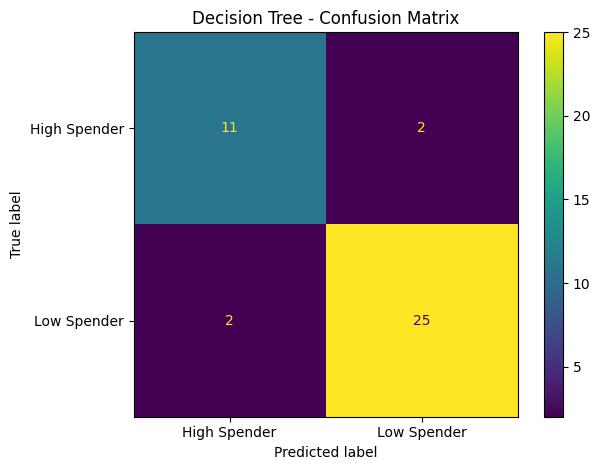

In [29]:
# Step 27: Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_tree)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=tree_model.classes_
)

disp.plot()

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

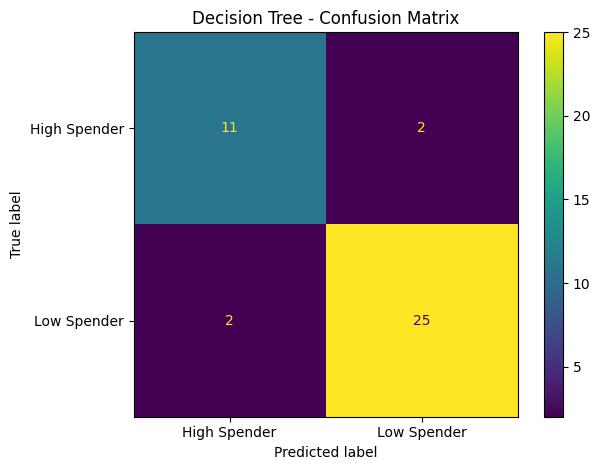

In [30]:
# Step 28: Save Decision Tree Confusion Matrix

cm = confusion_matrix(y_test, y_pred_tree)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=tree_model.classes_
)

disp.plot()

plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../Images/decision_tree_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Decision Tree ROC-AUC: 0.9131054131054132


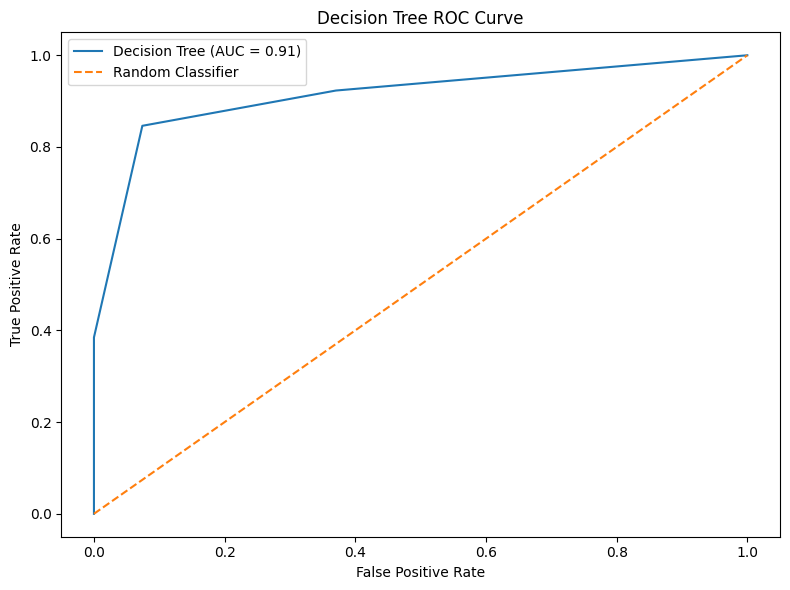

In [31]:
# Step 29: ROC Curve and ROC-AUC

from sklearn.metrics import roc_curve, roc_auc_score

# Get probability for High Spender
y_prob_tree = tree_model.predict_proba(X_test)[:, 0]

# Convert target to binary
y_test_binary = (y_test == "High Spender").astype(int)

# ROC values
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    y_prob_tree
)

# AUC score
auc_score = roc_auc_score(
    y_test_binary,
    y_prob_tree
)

print("Decision Tree ROC-AUC:", auc_score)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {auc_score:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve")
plt.legend()

plt.tight_layout()
plt.show()

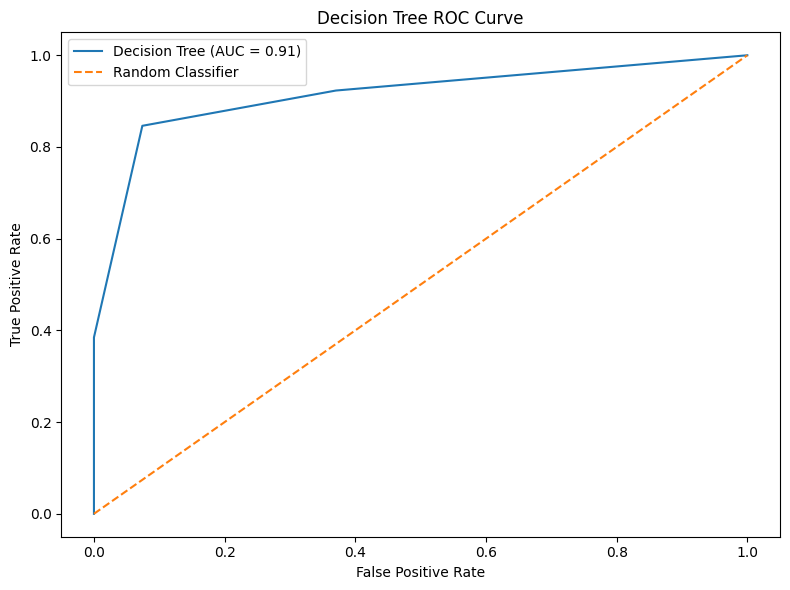

In [32]:
# Step 30: Save ROC Curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Decision Tree (AUC = {auc_score:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree ROC Curve")
plt.legend()

plt.tight_layout()

plt.savefig(
    "../Images/decision_tree_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
# Step 31: Feature Importance

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tree_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
              Feature  Importance
0                 Age    0.750394
1  Annual Income (k$)    0.249606
2         Gender_Male    0.000000


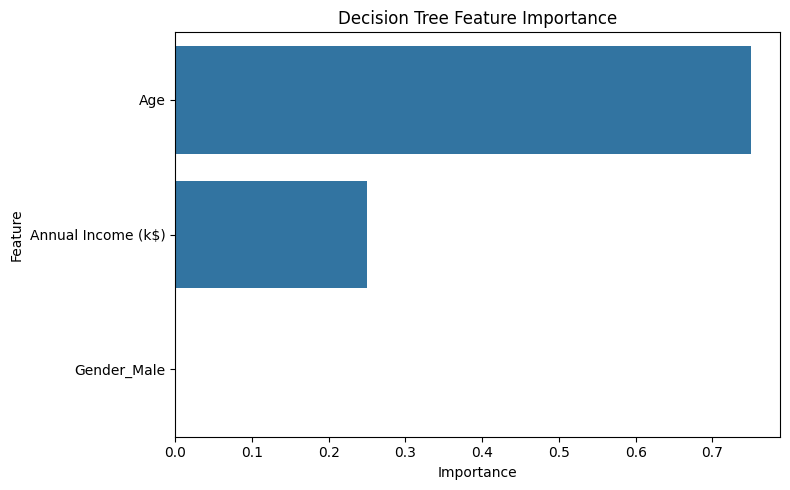

In [34]:
# Feature Importance Visualization

plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

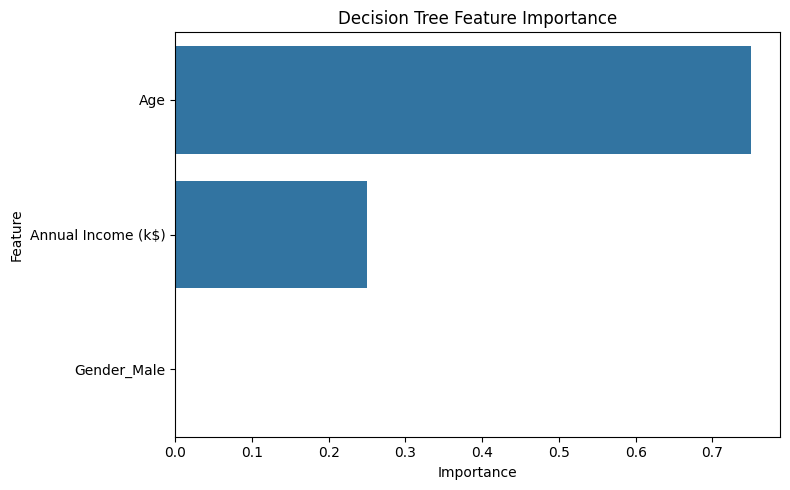

In [35]:
# Step 32: Save Feature Importance Chart

plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "../Images/decision_tree_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# Step 33: Cross-Validation

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    tree_model,
    X_encoded,
    y,
    cv=5,
    scoring="accuracy"
)

print("Cross-Validation Scores:")
print(cv_scores)

print("\nMean CV Accuracy:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

Cross-Validation Scores:
[0.6   0.725 0.675 0.75  0.7  ]

Mean CV Accuracy: 0.6900000000000001
Standard Deviation: 0.051478150704935006


In [37]:
# Step 34: Compare Models Using 5-Fold Cross-Validation

from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model
}

cv_results = {}

for name, model in models.items():
    
    scores = cross_val_score(
        model,
        X_encoded,
        y,
        cv=5,
        scoring="accuracy"
    )
    
    cv_results[name] = scores
    
    print(f"\n{name}")
    print("Scores:", scores)
    print("Mean Accuracy:", scores.mean())
    print("Std:", scores.std())


Logistic Regression
Scores: [0.675 0.65  0.5   0.475 0.75 ]
Mean Accuracy: 0.6100000000000001
Std: 0.10559356040971439

Decision Tree
Scores: [0.6   0.725 0.675 0.75  0.7  ]
Mean Accuracy: 0.6900000000000001
Std: 0.051478150704935006

Random Forest
Scores: [0.65  0.675 0.675 0.675 0.65 ]
Mean Accuracy: 0.6649999999999999
Std: 0.012247448713915901


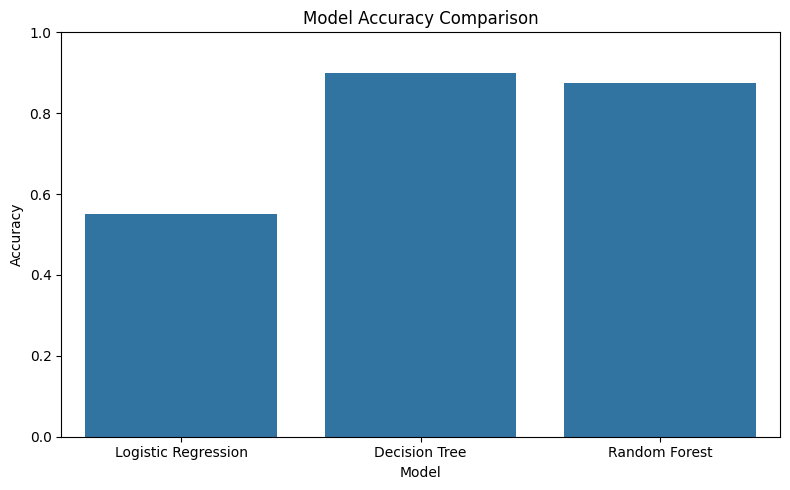

In [38]:
# Step 35: Model Comparison Chart

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        0.55,
        0.90,
        0.875
    ]
})

plt.figure(figsize=(8,5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylim(0,1)

plt.tight_layout()

plt.savefig(
    "../Images/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()